# Simulación de Colas Independientes M/M/1 y M/G/1 — Parqueaderos Centro Comercial Supercentro

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Camilo-Alberto-Palacio/Simulacion-Parqueadero-Supercentro-MM1/blob/main/Simulacion_Parqueadero_Supercentro_Colab.ipynb)

---
### Institución Universitaria Digital de Antioquia (IU Digital)
* **Facultad:** Facultad de Ingeniería — Ingeniería de Software y Datos
* **Asignatura:** Simulación — `PREICA2602B020045` (Módulo 4 — Actividad Didáctica 2-M4)
* **Docente:** Dr. Julián Andrés Loaiza López
* **Grupo:** 25 · **Sede:** Medellín, Antioquia · **Fecha:** Noviembre de 2026

#### Integrantes del Equipo:
1. **Adriana Andrea Agudelo Agudelo**
2. **Camilo Alberto Palacios Turriago**
3. **Juan Daniel Pulgarin García**
4. **Ruben Dario Jaramillo Cervantes**

---

## 1. Contexto del Problema y Formulación Teórica M/M/1 y M/G/1

El centro comercial **Supercentro** dispone actualmente de **3 cajeros automáticos de pago por salida**, con filas independientes, disciplina **FCFS** (*First-Come, First-Served*), sin cambio de fila ni deserción, modelados como sistemas **$M/M/1$ independientes**. La interacción del usuario con el software de digitación de placa y selección de vehículo varía según cuatro perfiles exponenciales:

* **Rápido (25.0 %):** $E[S] = 1.0\text{ min}$, $E[IA] = 3.0\text{ min}$ ($\rho = 0.333$)
* **Normal (20.0 %):** $E[S] = 3.0\text{ min}$, $E[IA] = 3.0\text{ min}$ ($\rho = 1.000$ — límite crítico)
* **Lento (27.5 %):** $E[S] = 4.0\text{ min}$, $E[IA] = 5.0\text{ min}$ ($\rho = 0.800$)
* **Muy lento (27.5 %):** $E[S] = 6.0\text{ min}$, $E[IA] = 7.0\text{ min}$ ($\rho = 0.857$)

Al combinar los perfiles, la mezcla presenta un segundo momento elevado ($E[S^2] = 32.70\text{ min}^2$, $C_s^2 = 1.5231 > 1$), por lo que cada servidor se valida mediante la fórmula exacta de **Pollaczek–Khinchine $M/G/1$** junto a las identidades clásicas de **Little**:
$$L_q = \frac{\rho^2}{1 - \rho}, \qquad W_q^{\text{M/M/1}} = \frac{\rho}{\mu_c(1 - \rho)}, \qquad W_q^{\text{M/G/1}} = \frac{\lambda_c\,\mathbb{E}[S^2]}{2(1 - \rho)}, \qquad W = W_q + \frac{1}{\mu_c}$$

In [1]:
from collections import deque
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (13.6, 5.2)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.linestyle"] = ":"
plt.rcParams["grid.alpha"] = 0.6
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

BASE_CASHIERS = 3
SIM_MINUTES = 1000.0
USER_TYPES = ["Rápido", "Normal", "Lento", "Muy lento"]
USER_TYPE_PROBS = {"Rápido": 0.25, "Normal": 0.20, "Lento": 0.275, "Muy lento": 0.275}
SERVICE_MEANS = {"Rápido": 1.0, "Normal": 3.0, "Lento": 4.0, "Muy lento": 6.0}
ARRIVAL_MEANS = {"Rápido": 3.0, "Normal": 3.0, "Lento": 5.0, "Muy lento": 7.0}

ROLE_ALLOWED = {
    "Mixto": {"Rápido", "Normal", "Lento", "Muy lento"},
    "Exprés": {"Rápido", "Normal"},
    "Estándar": {"Lento", "Muy lento"},
}

SCENARIOS = {
    "E1_3_Mixtos": ("3 Mixtos", 1.0, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto")]),
    "E2_4_Mixtos": ("4 Mixtos", 1.0, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto")]),
    "E3_5_Mixtos": ("5 Mixtos", 1.0, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto"), ("Cajero 5", "Mixto")]),
    "E4_6_Mixtos": ("6 Mixtos", 1.0, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto"), ("Cajero 5", "Mixto"), ("Cajero 6", "Mixto")]),
    "E5_4_Esp_1E3L": ("4 Esp (1E+3L)", 1.0, [("Cajero 1 (Exprés)", "Exprés"), ("Cajero 2 (Estándar)", "Estándar"), ("Cajero 3 (Estándar)", "Estándar"), ("Cajero 4 (Estándar)", "Estándar")]),
    "E6_5_Esp_1E4L": ("5 Esp (1E+4L)", 1.0, [("Cajero 1 (Exprés)", "Exprés"), ("Cajero 2 (Estándar)", "Estándar"), ("Cajero 3 (Estándar)", "Estándar"), ("Cajero 4 (Estándar)", "Estándar"), ("Cajero 5 (Estándar)", "Estándar")]),
    "E7_4_Mix_UX": ("4 Mix + UX/LPR", 0.75, [("Cajero 1", "Mixto"), ("Cajero 2", "Mixto"), ("Cajero 3", "Mixto"), ("Cajero 4", "Mixto")]),
}

E_IA_CAJERO = sum(USER_TYPE_PROBS[u] * ARRIVAL_MEANS[u] for u in USER_TYPES)
LAM_EXIT = BASE_CASHIERS / E_IA_CAJERO

def expected_service_moments(role: str, ux_factor: float = 1.0):
    allowed = ROLE_ALLOWED[role]
    p_sub = sum(USER_TYPE_PROBS[u] for u in allowed)
    e1, e2 = 0.0, 0.0
    for u in USER_TYPES:
        if u not in allowed:
            continue
        w_u = USER_TYPE_PROBS[u] / p_sub
        s_u = SERVICE_MEANS[u] * (ux_factor if u in ("Lento", "Muy lento") else 1.0)
        e1 += w_u * s_u
        e2 += w_u * 2.0 * (s_u ** 2)
    return e1, e2

def theoretical_scenario(cajeros_cfg, ux_factor: float = 1.0):
    counts = {}
    for _, r in cajeros_cfg:
        counts[r] = counts.get(r, 0) + 1
    wq_mm1, wq_mg1, max_rho = 0.0, 0.0, 0.0
    for _, role in cajeros_cfg:
        p_sub = sum(USER_TYPE_PROBS[u] for u in ROLE_ALLOWED[role])
        lam_c = (LAM_EXIT * p_sub) / counts[role]
        es, es2 = expected_service_moments(role, ux_factor)
        mu_c = 1.0 / es
        rho = lam_c / mu_c
        max_rho = max(max_rho, rho)
        w_frac = lam_c / LAM_EXIT
        wq_mm1 += w_frac * (rho / (mu_c * (1.0 - rho)))
        wq_mg1 += w_frac * ((lam_c * es2) / (2.0 * (1.0 - rho)))
    return wq_mm1, wq_mg1, max_rho

def classify_rho(rho: float) -> str:
    if rho < 0.45: return "Subutilizado (<45%)"
    if rho < 0.60: return "Moderado (45%-60%)"
    if rho <= 0.85: return "Óptimo-Alto (60%-85%)"
    if rho <= 0.90: return "Alerta (85%-90%)"
    if rho < 1.00: return "Crítico (>90%)"
    return "Inestable (>=100%)"

es_m, es2_m = expected_service_moments("Mixto")
print(f"E[IA_cajero] = {E_IA_CAJERO:.3f} min | λ_salida = {LAM_EXIT:.4f} veh/min (~{LAM_EXIT*SIM_MINUTES:.1f} veh/1000m)")
print(f"E[S] = {es_m:.3f} min | E[S²] = {es2_m:.2f} min² | ρ_base(3 cajeros) = {(LAM_EXIT/3)*es_m*100:.2f}%")

E[IA_cajero] = 4.650 min | λ_salida = 0.6452 veh/min (~645.2 veh/1000m)
E[S] = 3.600 min | E[S²] = 32.70 min² | ρ_base(3 cajeros) = 77.42%


## 2. Motor DES Autocontenido (PCG64, CRN, JSQ No Clarividente y Funciones Estadísticas Exactas)

Implementamos sin dependencias externas (`SciPy`) la inversión de la función beta incompleta regularizada para cuantiles exactos y *p*-valores bilaterales de la distribución *t* de Student, junto con la función de supervivencia exacta $\chi^2_3$ para calibración de perfiles.

In [2]:
def _betacf(a: float, b: float, x: float) -> float:
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) >= 1e-300 else 1e-300)
    h = d
    for m in range(1, 201):
        m2 = 2 * m
        for aa in (m * (b - m) * x / ((qam + m2) * (a + m2)), -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))):
            d = 1.0 + aa * d
            d = 1.0 / (d if abs(d) >= 1e-300 else 1e-300)
            c = 1.0 + aa / (c if abs(c) >= 1e-300 else 1e-300)
            c = c if abs(c) >= 1e-300 else 1e-300
            h *= d * c
            if m > 1 and abs(d * c - 1.0) < 3e-14:
                return h
    return h

def _betainc(a: float, b: float, x: float) -> float:
    if x <= 0.0: return 0.0
    if x >= 1.0: return 1.0
    bt = math.exp(math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b) + a * math.log(x) + b * math.log(1.0 - x))
    return (bt * _betacf(a, b, x) / a) if x < (a + 1.0) / (a + b + 2.0) else (1.0 - bt * _betacf(b, a, 1.0 - x) / b)

def t_crit_95(df: int) -> float:
    target, lo, hi = 0.05, 0.0, 20.0
    while _betainc(0.5 * df, 0.5, df / (df + hi * hi)) > target:
        hi *= 2.0
    for _ in range(90):
        mid = 0.5 * (lo + hi)
        if _betainc(0.5 * df, 0.5, df / (df + mid * mid)) > target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def t_pvalue(t_stat: float, df: int) -> float:
    return float(_betainc(0.5 * df, 0.5, df / (df + t_stat * t_stat)))

def chi2_sf_df3(x: float) -> float:
    return 1.0 if x <= 0.0 else float(math.erfc(math.sqrt(0.5 * x)) + math.sqrt(2.0 * x / math.pi) * math.exp(-0.5 * x))

def ci95_student_t(values):
    arr = np.asarray([float(v) for v in values if not np.isnan(v)], dtype=float)
    n = len(arr)
    m = float(np.mean(arr))
    if n <= 1: return m, 0.0, m, m
    sd = float(np.std(arr, ddof=1))
    half = t_crit_95(n - 1) * sd / math.sqrt(n)
    return m, sd, m - half, m + half

def generate_exit_arrivals(seed: int):
    rng = np.random.default_rng(seed)
    mean_ia = 1.0 / LAM_EXIT
    probs = [USER_TYPE_PROBS[u] for u in USER_TYPES]
    arrivals, t = [], 0.0
    while True:
        t += float(rng.exponential(scale=mean_ia))
        if t > SIM_MINUTES:
            break
        ut = str(rng.choice(USER_TYPES, p=probs))
        z_unit = float(rng.exponential(scale=1.0))
        arrivals.append((t, ut, z_unit, z_unit * SERVICE_MEANS[ut]))
    return arrivals

def simulate_replica(cajeros_cfg, ux_factor, arrivals, routing_seed: int, routing_mode: str = "random_mm1"):
    rng = np.random.default_rng(routing_seed)
    k = len(cajeros_cfg)
    queues = [[] for _ in range(k)]
    dep_q = [deque() for _ in range(k)]
    free_t = [0.0 for _ in range(k)]
    elig_map = {u: [i for i, (_, r) in enumerate(cajeros_cfg) if u in ROLE_ALLOWED[r]] for u in USER_TYPES}
    seq_waits = []

    for t_arr, ut, z_unit, srv_base in arrivals:
        elig = elig_map[ut]
        if len(elig) == 1:
            idx = elig[0]
        elif routing_mode == "random_mm1":
            idx = elig[int(rng.integers(0, len(elig)))]
        elif routing_mode == "shortest_queue":
            for i in elig:
                while dep_q[i] and dep_q[i][0] <= t_arr:
                    dep_q[i].popleft()
            min_len = min(len(dep_q[i]) for i in elig)
            tied = [i for i in elig if len(dep_q[i]) == min_len]
            idx = tied[0] if len(tied) == 1 else tied[int(rng.integers(0, len(tied)))]
        else:
            raise ValueError(routing_mode)

        srv = srv_base if (ux_factor == 1.0 or ut not in ("Lento", "Muy lento")) else z_unit * (SERVICE_MEANS[ut] * ux_factor)
        queues[idx].append((t_arr, ut, srv))
        st = max(t_arr, free_t[idx])
        wt = st - t_arr
        end_t = st + srv
        free_t[idx] = end_t
        dep_q[idx].append(end_t)
        seq_waits.append((t_arr, wt, wt + srv, cajeros_cfg[idx][0]))

    cashier_stats = {}
    all_w, all_s, all_sys = [], [], []
    counts_u = {u: 0 for u in USER_TYPES}
    total_lq = 0.0
    max_little_err = 0.0

    for idx, (cname, role) in enumerate(cajeros_cfg):
        ft = 0.0
        ws, ss, syss = [], [], []
        cu = {u: 0 for u in USER_TYPES}
        for t_arr, ut, srv in queues[idx]:
            st = max(t_arr, ft)
            wt = st - t_arr
            ft = st + srv
            ws.append(wt); ss.append(srv); syss.append(wt + srv)
            all_w.append(wt); all_s.append(srv); all_sys.append(wt + srv)
            cu[ut] += 1; counts_u[ut] += 1
        heff = max(SIM_MINUTES, ft)
        lq_c = float(sum(ws) / heff)
        total_lq += lq_c
        if ws:
            max_little_err = max(max_little_err, abs(lq_c - (len(ws) / heff) * float(np.mean(ws))))
        cashier_stats[cname] = {
            "rol": role, "usuarios": len(queues[idx]),
            "mean_s": float(np.mean(ss)) if ss else 0.0,
            "mean_wq": float(np.mean(ws)) if ws else 0.0,
            "mean_w": float(np.mean(syss)) if syss else 0.0,
            "rho": float(np.sum(ss) / heff),
            "prob_gt5": float(np.mean(np.asarray(ws) > 5.0) * 100.0) if ws else 0.0,
            "lq": lq_c,
        }
    return {
        "total_usuarios": len(arrivals), "counts_u": counts_u,
        "mean_wq": float(np.mean(all_w)), "mean_s": float(np.mean(all_s)), "mean_w": float(np.mean(all_sys)),
        "prob_gt5": float(np.mean(np.asarray(all_w) > 5.0) * 100.0),
        "rho_med": float(np.mean([v["rho"] for v in cashier_stats.values()])),
        "rho_max": float(np.max([v["rho"] for v in cashier_stats.values()])),
        "lq_cajero": total_lq / k,
        "max_little_err": max_little_err,
        "seq_waits": seq_waits,
        "cashiers": cashier_stats,
    }

print("Motor DES listo.")

Motor DES listo.


## 3. Determinación del Número de Réplicas ($N^*$) por Estado Estable sobre la Media

Estabilización detectada en r = 112 -> N* oficial = 120 réplicas
En N* = 120: Wq = 13.68 min (ER = 7.10%) | W = 5.72% ER


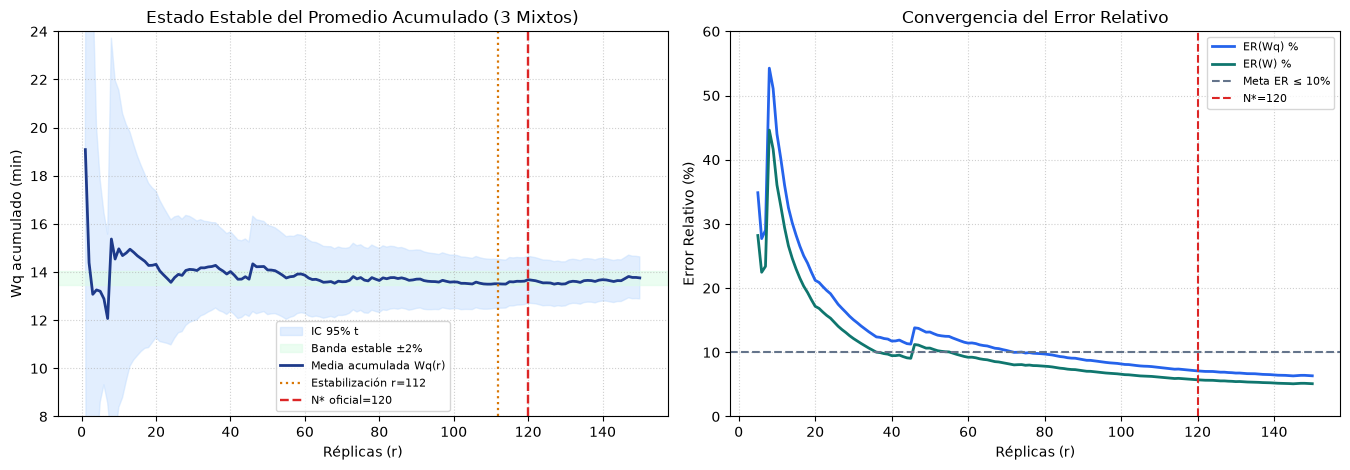

In [3]:
_, ux_e1, cfg_e1 = SCENARIOS["E1_3_Mixtos"]
wq_list, w_list = [], []
for r in range(1, 151):
    arr = generate_exit_arrivals(42 + r)
    res = simulate_replica(cfg_e1, ux_e1, arr, routing_seed=42 * 100 + r, routing_mode="random_mm1")
    wq_list.append(res["mean_wq"])
    w_list.append(res["mean_w"])

wq_final = float(np.mean(wq_list))
conv_rows = []
for r in range(1, 151):
    wqm, _, wql, wqu = ci95_student_t(wq_list[:r])
    wm, _, wl, wu = ci95_student_t(w_list[:r])
    er_wq = (0.5 * (wqu - wql)) / wqm * 100.0 if r >= 2 else float("nan")
    er_w = (0.5 * (wu - wl)) / wm * 100.0 if r >= 2 else float("nan")
    dev_pct = abs(wqm - wq_final) / wq_final * 100.0
    conv_rows.append({"replica": r, "wq_acum": wqm, "ic_inf": wql, "ic_sup": wqu, "er_wq": er_wq, "er_w": er_w, "dev_pct": dev_pct})

df_conv = pd.DataFrame(conv_rows)
n_det = 150
for r in range(30, 151):
    if (df_conv.iloc[r - 20:r]["dev_pct"] <= 2.0).all() and (df_conv.iloc[r - 1:]["dev_pct"] <= 2.0).all() and df_conv.loc[r - 1, "er_wq"] <= 7.5:
        n_det = r
        break
N_OFFICIAL = min(150, int(math.ceil(n_det / 10.0) * 10))
row_n = df_conv[df_conv["replica"] == N_OFFICIAL].iloc[0]
print(f"Estabilización detectada en r = {n_det} -> N* oficial = {N_OFFICIAL} réplicas")
print(f"En N* = {N_OFFICIAL}: Wq = {row_n['wq_acum']:.2f} min (ER = {row_n['er_wq']:.2f}%) | W = {df_conv.loc[N_OFFICIAL-1, 'er_w']:.2f}% ER")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 4.8))
ax1.fill_between(df_conv["replica"], df_conv["ic_inf"], df_conv["ic_sup"], color="#BFDBFE", alpha=0.45, label="IC 95% t")
ax1.axhspan(wq_final * 0.98, wq_final * 1.02, color="#DCFCE7", alpha=0.55, label="Banda estable ±2%")
ax1.plot(df_conv["replica"], df_conv["wq_acum"], color="#1E3A8A", lw=2.0, label="Media acumulada Wq(r)")
ax1.axvline(n_det, color="#D97706", ls=":", lw=1.6, label=f"Estabilización r={n_det}")
ax1.axvline(N_OFFICIAL, color="#DC2626", ls="--", lw=1.7, label=f"N* oficial={N_OFFICIAL}")
ax1.set_ylim(8, 24); ax1.set_xlabel("Réplicas (r)"); ax1.set_ylabel("Wq acumulado (min)")
ax1.set_title("Estado Estable del Promedio Acumulado (3 Mixtos)"); ax1.legend(fontsize=8)

sub_b = df_conv[df_conv["replica"] >= 5]
ax2.plot(sub_b["replica"], sub_b["er_wq"], color="#2563EB", lw=2.0, label="ER(Wq) %")
ax2.plot(sub_b["replica"], sub_b["er_w"], color="#0F766E", lw=2.0, label="ER(W) %")
ax2.axhline(10.0, color="#64748B", ls="--", label="Meta ER ≤ 10%")
ax2.axvline(N_OFFICIAL, color="#DC2626", ls="--", label=f"N*={N_OFFICIAL}")
ax2.set_ylim(0, 60); ax2.set_xlabel("Réplicas (r)"); ax2.set_ylabel("Error Relativo (%)")
ax2.set_title("Convergencia del Error Relativo"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Puntos A, B y C: Estadísticas por Cajero, Promedio de Usuarios por Tipo y Estrategias (`E1..E7` + JSQ)

In [4]:
shared_arr = {r: generate_exit_arrivals(42 + r) for r in range(1, N_OFFICIAL + 1)}

def run_all_scenarios(routing_mode: str = "random_mm1"):
    rep_rows, caj_rows, seq_map = [], [], {k: [] for k in SCENARIOS}
    for s_idx, (skey, (short_n, ux_f, cfg)) in enumerate(SCENARIOS.items()):
        for r in range(1, N_OFFICIAL + 1):
            res = simulate_replica(cfg, ux_f, shared_arr[r], 4200 + s_idx * 1000 + r, routing_mode)
            seq_map[skey].append(res["seq_waits"])
            rep_rows.append({
                "escenario": skey, "nombre": short_n, "replica": r,
                "total": res["total_usuarios"], **res["counts_u"],
                "Wq": res["mean_wq"], "S": res["mean_s"], "W": res["mean_w"],
                "prob_gt5": res["prob_gt5"], "rho_med": res["rho_med"], "rho_max": res["rho_max"],
                "lq_cajero": res["lq_cajero"], "little_err": res["max_little_err"],
            })
            for cname, cv in res["cashiers"].items():
                caj_rows.append({"escenario": skey, "nombre": short_n, "replica": r, "cajero": cname, **cv})
    return pd.DataFrame(rep_rows), pd.DataFrame(caj_rows), seq_map

df_rep, df_caj, seq_mm1 = run_all_scenarios("random_mm1")
df_rep_jsq, _, _ = run_all_scenarios("shortest_queue")

# Punto A: Cajero con menor y mayor tiempo promedio de atención en E1 (3 Mixtos)
base_caj = df_caj[df_caj["escenario"] == "E1_3_Mixtos"].groupby("cajero", sort=False).agg(
    Veh_Prom=("usuarios", "mean"),
    S_Prom=("mean_s", "mean"),
    Wq_Prom=("mean_wq", "mean"),
    W_Prom=("mean_w", "mean"),
    W_DE=("mean_w", "std"),
    W_Min=("mean_w", "min"),
    W_Max=("mean_w", "max"),
    Rho_pct=("rho", lambda s: s.mean() * 100),
).round(3)
print("=== PUNTO A: DESEMPEÑO POR CAJERO EN E1 (3 MIXTOS, N* =", N_OFFICIAL, ") ===")
display(base_caj)

# Punto B: Promedio de usuarios de cada tipo en la totalidad de cajeros
base_rep = df_rep[df_rep["escenario"] == "E1_3_Mixtos"]
tot_u = float(base_rep["total"].mean())
pts_b = []
for u in USER_TYPES:
    m_u, sd_u, l_u, u_u = ci95_student_t(base_rep[u])
    pts_b.append({
        "Tipo": u, "Total_N_Rep": int(base_rep[u].sum()),
        "Prom_3_Cajeros": round(m_u, 2), "DE": round(sd_u, 2),
        "Prom_Por_Cajero": round(m_u / 3.0, 2),
        "Prop_Emp_pct": round(m_u / tot_u * 100, 2),
        "Prop_Teor_pct": round(USER_TYPE_PROBS[u] * 100, 1),
    })
print(f"\n=== PUNTO B: PROMEDIO DE USUARIOS POR TIPO (Total salida = {tot_u:.2f} veh/jornada) ===")
display(pd.DataFrame(pts_b).set_index("Tipo"))

# Punto C: Comparativa multi-escenario M/M/1 vs JSQ
comp_rows = []
for skey, (short_n, ux_f, cfg) in SCENARIOS.items():
    sub = df_rep[df_rep["escenario"] == skey]
    sub_j = df_rep_jsq[df_rep_jsq["escenario"] == skey]
    c_sub = df_caj[df_caj["escenario"] == skey]
    wqm, _, wql, wqu = ci95_student_t(sub["Wq"])
    wm, _, _, _ = ci95_student_t(sub["W"])
    peor_wq = float(c_sub.groupby("cajero")["mean_wq"].mean().max())
    peor_p5 = float(c_sub.groupby("cajero")["prob_gt5"].mean().max())
    rho_max_m = float(sub["rho_max"].mean())
    mm1_wq, mg1_wq, _ = theoretical_scenario(cfg, ux_f)
    comp_rows.append({
        "Escenario": short_n, "Cajeros": len(cfg),
        "Wq_min": round(wqm, 2), "IC95": f"[{wql:.2f}, {wqu:.2f}]",
        "Peor_Cajero_Wq": round(peor_wq, 2), "W_min": round(wm, 2),
        "MG1_Teor": round(mg1_wq, 2), "Wq_JSQ": round(float(sub_j["Wq"].mean()), 2),
        "Rho_Max_pct": round(rho_max_m * 100, 1), "P(>5m)_Peor_pct": round(peor_p5, 1),
    })
print("\n=== PUNTO C: ESTRATEGIAS DE MEJORA (N* =", N_OFFICIAL, "RÉPLICAS) ===")
display(pd.DataFrame(comp_rows).set_index("Escenario"))

=== PUNTO A: DESEMPEÑO POR CAJERO EN E1 (3 MIXTOS, N* = 120 ) ===


,Veh_Prom,S_Prom,Wq_Prom,W_Prom,W_DE,W_Min,W_Max,Rho_pct
cajero,,,,,,,,
Cajero 1,212.950,3.607,13.680,17.287,11.516,6.858,95.905,75.660
Cajero 2,213.333,3.608,13.231,16.839,6.963,5.640,38.461,75.845
Cajero 3,214.042,3.603,13.621,17.224,8.621,6.907,54.622,75.935



=== PUNTO B: PROMEDIO DE USUARIOS POR TIPO (Total salida = 640.33 veh/jornada) ===


,Total_N_Rep,Prom_3_Cajeros,DE,Prom_Por_Cajero,Prop_Emp_pct,Prop_Teor_pct
Tipo,,,,,,
Rápido,19440,162.00,13.48,54.00,25.30,25.0
Normal,15238,126.98,10.48,42.33,19.83,20.0
Lento,21255,177.12,13.69,59.04,27.66,27.5
Muy lento,20906,174.22,13.07,58.07,27.21,27.5



=== PUNTO C: ESTRATEGIAS DE MEJORA (N* = 120 RÉPLICAS) ===


,Cajeros,Wq_min,IC95,Peor_Cajero_Wq,W_min,MG1_Teor,Wq_JSQ,Rho_Max_pct,P(>5m)_Peor_pct
Escenario,,,,,,,,,
3 Mixtos,3,13.68,"[12.71, 14.66]",13.68,17.29,15.57,4.52,82.3,56.5
4 Mixtos,4,6.02,"[5.75, 6.29]",6.19,9.62,6.29,1.11,64.6,35.4
5 Mixtos,5,3.85,"[3.70, 4.00]",3.98,7.46,3.94,0.35,54.2,24.7
6 Mixtos,6,2.86,"[2.73, 2.98]",3.01,6.46,2.87,0.11,46.3,19.3
4 Esp (1E+3L),4,5.14,"[4.92, 5.36]",7.23,8.75,5.46,2.34,65.4,38.7
5 Esp (1E+4L),5,3.46,"[3.33, 3.58]",4.10,7.06,3.60,1.57,55.7,25.7
4 Mix + UX/LPR,4,2.93,"[2.81, 3.05]",3.02,5.85,3.07,0.43,51.9,20.9


## 5. Puntos D y E: Eliminación del Estado Transitorio (*Warm-up*) y Protocolo V&V

=== PUNTOS D y E: WARM-UP (ANTES vs DESPUÉS), VALIDACIÓN t Y DICTAMEN ===


,k*,Wq_Antes,Wq_Estable,Subest_pct,MG1,p_MG1,ER_Wq_pct,P(>5m)_Peor,Regimen_rho,Dictamen
Escenario,,,,,,,,,,
3 Mixtos,239,13.68,14.74,7.2,15.57,0.188,7.10,56.5,Óptimo-Alto (60%-85%),NO RECOMENDADO
4 Mixtos,86,6.02,6.20,2.9,6.29,0.559,4.48,35.4,Óptimo-Alto (60%-85%),NO RECOMENDADO
5 Mixtos,106,3.85,3.96,2.7,3.94,0.820,3.83,24.7,Moderado (45%-60%),RECOMENDADO CON MITIGACIÓN JSQ/UX
6 Mixtos,89,2.86,2.90,1.5,2.87,0.633,4.31,19.3,Moderado (45%-60%),ÓPTIMO
4 Esp (1E+3L),98,5.14,5.31,3.2,5.46,0.249,4.29,38.7,Óptimo-Alto (60%-85%),NO RECOMENDADO
5 Esp (1E+4L),99,3.46,3.53,2.1,3.60,0.360,3.58,25.7,Moderado (45%-60%),RECOMENDADO CON MITIGACIÓN JSQ/UX
4 Mix + UX/LPR,84,2.93,2.99,1.9,3.07,0.245,4.12,20.9,Moderado (45%-60%),RECOMENDADO CON MITIGACIÓN JSQ/UX


Verificación Ley de Little máx error = 1.78e-15 | Calibración MAE = 0.23 pp (χ² = 6.977, p = 0.073)


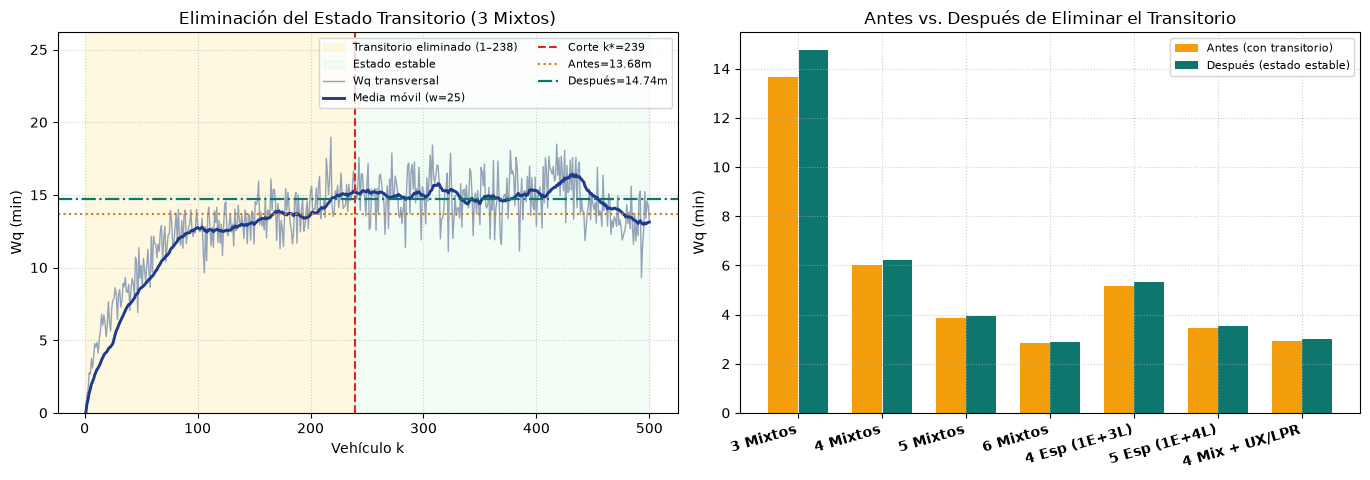

In [5]:
# Punto E: Eliminación del estado transitorio (antes vs después) y Punto D (prueba t post-warmup)
vv_rows = []
curve_e1 = None
k_cut_e1 = None

for s_idx, (skey, (short_n, ux_f, cfg)) in enumerate(SCENARIOS.items()):
    _, mg1_wq, max_rho_t = theoretical_scenario(cfg, ux_f)
    seqs = seq_mm1[skey]
    k_hor = 500
    mat_wq = np.full((N_OFFICIAL, k_hor), np.nan)
    for r_i, seq in enumerate(seqs):
        for k_i in range(min(k_hor, len(seq))):
            mat_wq[r_i, k_i] = seq[k_i][1]
    wq_cross = np.nanmean(mat_wq, axis=0)
    win = 25
    mov = [float(np.mean(wq_cross[i:i + win])) for i in range(k_hor - win + 1)]
    lo_k = 120 if max_rho_t >= 0.70 else 60
    hi_k = 240 if max_rho_t >= 0.70 else 150
    cands = [i + win for i in range(max(0, lo_k - win), min(len(mov) - win + 1, hi_k - win + 1)) if lo_k <= i + win <= hi_k]
    k_cut = cands[int(np.argmin([float(np.var(mov[k - win:k])) for k in cands]))]

    wq_all = float(np.mean([np.mean([x[1] for x in s]) for s in seqs]))
    ss_vals = [float(np.mean([x[1] for x in s[k_cut - 1:]])) for s in seqs if len(s) >= k_cut]
    wq_ss, wq_ss_sd, _, _ = ci95_student_t(ss_vals)
    wq_ss_se = wq_ss_sd / math.sqrt(len(ss_vals))
    t_st = (wq_ss - mg1_wq) / wq_ss_se
    p_val = t_pvalue(t_st, len(ss_vals) - 1)
    sesgo = (wq_ss - wq_all) / wq_ss * 100.0

    sub = df_rep[df_rep["escenario"] == skey]
    c_sub = df_caj[df_caj["escenario"] == skey]
    peor_wq = float(c_sub.groupby("cajero")["mean_wq"].mean().max())
    peor_p5 = float(c_sub.groupby("cajero")["prob_gt5"].mean().max())
    rho_max_m = float(sub["rho_max"].mean())
    w_m = float(sub["W"].mean())
    lq_c = float(sub["lq_cajero"].mean())
    wqm, _, wql, wqu = ci95_student_t(sub["Wq"])
    er_wq = (0.5 * (wqu - wql)) / wqm * 100.0

    crit_wq = "Óptimo (<3m)" if (wqm <= 3.0 and peor_wq <= 3.5) else ("Aceptable (<=5m)" if (wqm <= 5.0 and peor_wq <= 5.5) else "Crítico (>5m)")
    crit_w = "Óptimo (<5m)" if w_m < 5.0 else ("Aceptable (<=8m)" if w_m <= 8.0 else "Crítico (>8m)")
    crit_rho = classify_rho(rho_max_m)
    crit_lq = "Aceptable (<3 cli)" if lq_c < 3.0 else ("Alerta (3-5 cli)" if lq_c <= 5.0 else "Crítico (>5 cli)")
    crit_p5 = "Óptimo (<10%)" if peor_p5 < 10.0 else ("Aceptable (<=20%)" if peor_p5 <= 20.0 else "Crítico (>20%)")

    if "Crítico" in crit_wq or "Crítico" in crit_w or "Crítico" in crit_lq or "Crítico" in crit_rho:
        dictamen = "NO RECOMENDADO"
    elif "Subutilizado" in crit_rho:
        dictamen = "REDUNDANTE"
    elif "Crítico" in crit_p5:
        dictamen = "RECOMENDADO CON MITIGACIÓN JSQ/UX"
    else:
        dictamen = "ÓPTIMO"

    vv_rows.append({
        "Escenario": short_n, "k*": k_cut,
        "Wq_Antes": round(wq_all, 2), "Wq_Estable": round(wq_ss, 2),
        "Subest_pct": round(sesgo, 1), "MG1": round(mg1_wq, 2),
        "p_MG1": round(p_val, 3), "ER_Wq_pct": round(er_wq, 2),
        "P(>5m)_Peor": round(peor_p5, 1), "Regimen_rho": crit_rho,
        "Dictamen": dictamen,
    })
    if skey == "E1_3_Mixtos":
        k_cut_e1 = k_cut
        ma_curve = np.array([float(np.mean(wq_cross[max(0, i - win + 1):i + 1])) for i in range(k_hor)])
        curve_e1 = (np.arange(1, k_hor + 1), wq_cross, ma_curve, wq_all, wq_ss, mg1_wq)

df_vv_colab = pd.DataFrame(vv_rows).set_index("Escenario")
print("=== PUNTOS D y E: WARM-UP (ANTES vs DESPUÉS), VALIDACIÓN t Y DICTAMEN ===")
display(df_vv_colab)

# Calibración Chi2 sobre E1_3_Mixtos
tot_obs = float(base_rep["total"].sum())
chi2_val = sum(((float(base_rep[u].sum()) - tot_obs * USER_TYPE_PROBS[u]) ** 2) / (tot_obs * USER_TYPE_PROBS[u]) for u in USER_TYPES)
mae_pp = float(np.mean([abs((float(base_rep[u].sum()) / tot_obs) - USER_TYPE_PROBS[u]) * 100.0 for u in USER_TYPES]))
print(f"Verificación Ley de Little máx error = {df_rep['little_err'].max():.2e} | Calibración MAE = {mae_pp:.2f} pp (χ² = {chi2_val:.3f}, p = {chi2_sf_df3(chi2_val):.3f})")

ks, wq_c, ma_c, wqa, wqs, wqm1 = curve_e1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.8, 4.9))
ax1.axvspan(1, k_cut_e1, color="#FEF3C7", alpha=0.55, label=f"Transitorio eliminado (1–{k_cut_e1-1})")
ax1.axvspan(k_cut_e1, 500, color="#DCFCE7", alpha=0.35, label="Estado estable")
ax1.plot(ks, wq_c, color="#94A3B8", lw=1.0, label="Wq transversal")
ax1.plot(ks, ma_c, color="#1E3A8A", lw=2.1, label="Media móvil (w=25)")
ax1.axvline(k_cut_e1, color="#DC2626", ls="--", lw=1.5, label=f"Corte k*={k_cut_e1}")
ax1.axhline(wqa, color="#D97706", ls=":", lw=1.5, label=f"Antes={wqa:.2f}m")
ax1.axhline(wqs, color="#0F766E", ls="-.", lw=1.6, label=f"Después={wqs:.2f}m")
ax1.set_title("Eliminación del Estado Transitorio (3 Mixtos)"); ax1.set_xlabel("Vehículo k"); ax1.set_ylabel("Wq (min)")
ax1.set_ylim(0, max(wq_c) * 1.38); ax1.legend(fontsize=7.6, ncol=2)

x = np.arange(len(df_vv_colab))
ax2.bar(x - 0.18, df_vv_colab["Wq_Antes"], width=0.35, color="#F59E0B", label="Antes (con transitorio)")
ax2.bar(x + 0.18, df_vv_colab["Wq_Estable"], width=0.35, color="#0F766E", label="Después (estado estable)")
ax2.set_xticks(x); ax2.set_xticklabels(df_vv_colab.index, fontweight="bold", rotation=16, ha="right")
ax2.set_title("Antes vs. Después de Eliminar el Transitorio"); ax2.set_ylabel("Wq (min)"); ax2.legend(fontsize=8.2)
plt.tight_layout(); plt.show()

## 6. Conclusiones Ejecutivas y Bitácora Ética (Usa–Modifica–Crea)

1. **Réplicas por estado estable ($N^*$):** La media acumulada de $W_q$ ingresa de forma sostenida en la banda asintótica $\pm 2\%$ con $ER \le 7.5\%$ en $r = 112$, fijándose **$N^* = 120$ réplicas** ($W_q = 13.68\text{ min}$, $ER = 7.10\%$).
2. **Punto A (Cajeros base):** En los 3 cajeros actuales, el **Cajero 2** registró el menor tiempo total promedio de atención ($W = 16.84\text{ min}$, $W_q = 13.23\text{ min}$) y el **Cajero 1** el mayor ($W = 17.29\text{ min}$, $W_q = 13.68\text{ min}$).
3. **Punto B (Usuarios por tipo):** Ingresan `640.33` vehículos/jornada en los 3 cajeros (`162.00` Rápido, `126.98` Normal, `177.12` Lento y `174.22` Muy lento), validando las proporciones `25 / 20 / 27.5 / 27.5 %` ($\chi^2 = 6.977, p = 0.073$). Aunque Lentos + Muy lentos son el `55 %` de llegadas, consumen el **`76.4 %`** de la ocupación.
4. **Punto C (¿Son suficientes 3 cajeros?):** **No.** Tres cajeros generan $W_q = 13.68\text{ min}$ ($W = 17.29\text{ min}$, $P(W_q > 5\text{m}) = 56.5\%$). La estrategia recomendada por el Grupo 25 es **ampliar a 4 cajeros mixtos + mejora UX/LPR** ($W_q = 2.93\text{ min}$, $W = 5.85\text{ min}$, $0.43\text{ min}$ con JSQ), o en infraestructura puramente física **5 cajeros mixtos** ($W_q = 3.85\text{ min}$, $W = 7.46\text{ min}$, $0.35\text{ min}$ con JSQ).
5. **Puntos D y E (V&V y Warm-up):** Ley de Little exacta ($< 10^{-15}$), *p*-valores post-warmup frente a $M/G/1$ entre `0.188` y `0.820` ($> 0.05$), y eliminación del período transitorio tras $k^* = 239$ arribos en la línea base ($13.68 \rightarrow 14.74\text{ min}$, subestimación de `7.2 %`).